<a href="https://colab.research.google.com/github/ahmedaeldahmy/AAI-521-Group4-Eurosat/blob/main/notebooks/03_Sai_EfficientNetB0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model C: EfficientNetB0 Transfer Learning on EuroSAT

**AAI-521, Group 4 | Sai Gautham Bandi**

**Team:** Ahmed Eldahmy, Akua Duffour, Sai Gautham Bandi

This notebook trains Model C, an ImageNet-pretrained EfficientNetB0, on the
team's shared EuroSAT split (`data/split.csv`, seed 42). It uses the same
train, validation, and test images as Model A (CNN) and Model B (MobileNetV2),
so the three test scores are directly comparable.

What this notebook adds beyond a single training run:

1. **Two-stage transfer learning.** Train a new head on frozen features, then
   fine-tune the whole backbone with BatchNorm statistics frozen.
2. **Repeated runs.** The final setup is retrained with three seeds, and the
   score is reported as mean ± standard deviation.
3. **An input-resolution study.** EuroSAT tiles are 64 × 64, but ImageNet
   models were trained at 224 × 224. I test 64, 128, and 224 to see how much
   upsampling matters.
4. **Error analysis and Grad-CAM** to see which classes fail and where the
   model looks.

> **AI-assistance disclosure:** Claude Code (Anthropic) helped draft parts of
> this notebook's code and text. I reviewed, ran, and checked every cell, and
> the results below come from my own runs.

## 1. Environment and imports

Keras 3 can run on TensorFlow, JAX, or PyTorch. On Colab the notebook uses
TensorFlow, like the rest of the team. TensorFlow has no GPU support on native
Windows, so on my local Windows machine I run the same Keras code on the
PyTorch backend, which can use the AMD GPU through ROCm. The code below uses
only backend-neutral Keras APIs. The one exception is Grad-CAM in Section 10,
which has a small branch for each backend.

In [1]:
import os
import platform
import sys

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/working")

if "KERAS_BACKEND" not in os.environ:
    os.environ["KERAS_BACKEND"] = "tensorflow"
    if platform.system() == "Windows":
        try:
            import torch

            if torch.cuda.is_available():
                os.environ["KERAS_BACKEND"] = "torch"
        except ImportError:
            pass

if os.environ["KERAS_BACKEND"] == "torch":
    import torch

    # MIOpen's BatchNorm kernels crash on this AMD GPU, so fall back to the
    # native PyTorch kernels. This has no effect on NVIDIA/Colab machines.
    if torch.version.hip:
        torch.backends.cudnn.enabled = False

In [2]:
import json
import hashlib
import subprocess
import time
import zipfile
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras import layers
from PIL import Image
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

SEED = 42
keras.utils.set_random_seed(SEED)
BACKEND = keras.backend.backend()

print("Python:", sys.version.split()[0])
print("Keras:", keras.__version__, "| backend:", BACKEND)
if BACKEND == "torch":
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available()
          else "none")
else:
    import tensorflow as tf

    print("TensorFlow:", tf.__version__)
    print("GPU:", tf.config.list_physical_devices("GPU"))

Python: 3.13.5
Keras: 3.15.1 | backend: torch
GPU: AMD Radeon(TM) 8060S Graphics


## 2. Find the repository and the dataset

The notebook first looks for the cloned repository, which has `data/split.csv`.
In Colab or Kaggle, it clones the repository if it cannot find it. The images
come from the official Zenodo ZIP, checked with the same MD5 that Ahmed used,
and are extracted into `raw_dataset/`. That folder is not committed to Git.

In [3]:
REPO_URL = "https://github.com/ahmedaeldahmy/AAI-521-Group4-Eurosat.git"
candidates = [
    Path("/content/AAI-521-Group4-Eurosat"),
    Path("/kaggle/working/AAI-521-Group4-Eurosat"),
    Path.cwd(),
    Path.cwd().parent,
]
REPO = next(
    (p for p in candidates if (p / "data" / "split.csv").exists()), None
)
if REPO is None:
    if not (IN_COLAB or IN_KAGGLE):
        raise FileNotFoundError("Run this notebook from inside the repo.")
    REPO = candidates[0] if IN_COLAB else candidates[1]
    subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)

RAW_DIR = REPO / "raw_dataset"
RESULTS_DIR = REPO / "results"
MODELS_DIR = REPO / "models"
for folder in (RAW_DIR, RESULTS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Repository:", REPO)

Repository: C:\mycode\msaai521_cv\final_project\project


In [4]:
DATA_URL = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"
ZIP_PATH = RAW_DIR / "EuroSAT_RGB.zip"
EXPECTED_MD5 = "f46e308c4d50d4bf32fedad2d3d62f3b"


def md5_of(path):
    """Return the MD5 hex digest of a file, read in 1 MB blocks."""
    digest = hashlib.md5()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


if not ZIP_PATH.exists():
    import requests

    print("Downloading EuroSAT RGB from Zenodo (about 95 MB)...")
    partial = RAW_DIR / "EuroSAT_RGB.download"
    with requests.get(DATA_URL, stream=True, timeout=(30, 300),
                      headers={"User-Agent": "Mozilla/5.0"}) as response:
        response.raise_for_status()
        with partial.open("wb") as out:
            for block in response.iter_content(chunk_size=1024 * 1024):
                out.write(block)
    partial.replace(ZIP_PATH)

assert md5_of(ZIP_PATH) == EXPECTED_MD5, "ZIP checksum does not match Zenodo."

marker = RAW_DIR / "extraction_complete.txt"
if not marker.exists():
    with zipfile.ZipFile(ZIP_PATH) as archive:
        base = RAW_DIR.resolve()
        for item in archive.infolist():
            # Refuse entries that would be written outside RAW_DIR.
            assert (RAW_DIR / item.filename).resolve().is_relative_to(base)
        archive.extractall(RAW_DIR)
    marker.write_text("EuroSAT RGB extracted\n", encoding="utf-8")
print("Images ready in:", RAW_DIR)

Images ready in: C:\mycode\msaai521_cv\final_project\project\raw_dataset


## 3. Load the shared split into memory

EuroSAT is small: 27,000 RGB tiles of 64 × 64 pixels, or about 330 MB as
`uint8`. So I load each split into a NumPy array once. That makes every epoch
read from memory instead of decoding JPEGs again. It also lets the same code
run on every Keras backend. The labels come from `split.csv`, and I check
them against `class_map.json`.

In [5]:
split_df = pd.read_csv(REPO / "data" / "split.csv")
class_map = json.loads((REPO / "data" / "class_map.json").read_text())
CLASS_NAMES = class_map["class_names"]
NUM_CLASSES = len(CLASS_NAMES)

assert class_map["split_seed"] == 42
assert split_df["filename"].is_unique
assert (split_df["class_name"].map(class_map["name_to_id"])
        == split_df["label"]).all(), "Labels disagree with class_map.json"


def load_split_arrays(split):
    """Load one split as (images uint8 [N,64,64,3], labels int32, filenames)."""
    part = split_df.loc[split_df["split"] == split].reset_index(drop=True)
    images = np.empty((len(part), 64, 64, 3), dtype=np.uint8)
    for i, name in enumerate(part["filename"]):
        with Image.open(RAW_DIR / name) as img:
            images[i] = np.asarray(img.convert("RGB"))
    return images, part["label"].to_numpy("int32"), part["filename"].to_numpy()


start = time.time()
x_train, y_train, f_train = load_split_arrays("train")
x_val, y_val, f_val = load_split_arrays("val")
x_test, y_test, f_test = load_split_arrays("test")
print(f"Loaded in {time.time() - start:.1f}s")
for name, y in (("train", y_train), ("val", y_val), ("test", y_test)):
    print(f"{name:>5}: {len(y):>6} images, per-class counts "
          f"{np.bincount(y, minlength=NUM_CLASSES).tolist()}")

# No image may appear in more than one split, or the test score would leak.
assert not (set(f_train) & set(f_val) or set(f_train) & set(f_test)
            or set(f_val) & set(f_test))

Loaded in 4.0s
train:  18900 images, per-class counts [2100, 2100, 2100, 1750, 1750, 1400, 1750, 2100, 1750, 2100]
  val:   4050 images, per-class counts [450, 450, 450, 375, 375, 300, 375, 450, 375, 450]
 test:   4050 images, per-class counts [450, 450, 450, 375, 375, 300, 375, 450, 375, 450]


## 4. Why EfficientNetB0?

**Compound scaling.** Tan and Le (2019) found that a CNN works best when its
depth $d$, width $w$, and input resolution $r$ grow together. They scale all
three with one coefficient $\phi$:

$$d = \alpha^{\phi},\quad w = \beta^{\phi},\quad r = \gamma^{\phi},
\qquad \text{s.t.}\ \alpha\cdot\beta^{2}\cdot\gamma^{2}\approx 2,\ \
\alpha,\beta,\gamma \ge 1 .$$

FLOPs grow roughly with $d\,w^{2}r^{2}$, so each step of $\phi$ about doubles
the compute. B0 is the base network ($\phi=0$), found by neural architecture
search. Without its 1,000-class ImageNet head it has 4.05 M parameters, and
it needs 0.39 GFLOPs per image at 224 px. Without their heads, MobileNetV2
has 2.26 M parameters and our scratch CNN has 1.14 M.

**Building block.** B0 stacks MBConv blocks, the inverted residual block from
MobileNetV2:

1. A 1 × 1 expansion convolution (×6 channels).
2. A depthwise $k \times k$ convolution.
3. A squeeze-and-excitation (SE) gate.
4. A 1 × 1 linear projection, plus a skip connection when the input and output
   shapes match.

The SE gate reweights channels with
$s = \sigma\big(W_2\,\delta(W_1\,\mathrm{GAP}(U))\big)$ and outputs
$\tilde U_c = s_c U_c$. In words, the network learns which feature maps
matter for the current image. This should help with EuroSAT, where texture
and colour cues, such as field patterns or water, decide the class. The
activation is SiLU/Swish, $x\,\sigma(x)$.

**Transfer learning.** The backbone keeps its ImageNet weights. I replace the
1,000-class head with global average pooling, dropout of 0.3, and a 10-way
softmax:
$p(y=k\mid x)=\exp(z_k)/\sum_j \exp(z_j)$. Training minimises the
cross-entropy $\mathcal L = -\frac1N\sum_i \log p(y_i\mid x_i)$.

**Input pipeline.** The model takes the raw 64 × 64 `uint8` tile and applies:

1. Random horizontal and vertical flips plus a ±36° rotation with reflect
   padding, only while training. An overhead image has no "up", so these keep
   the label the same.
2. A bilinear resize to the backbone resolution.
3. EfficientNet's built-in rescaling and ImageNet normalisation, which are
   part of the Keras model, so no separate `preprocess_input` is needed.

In [6]:
IMG_SIZE = 224          # main configuration (same as Model B)
BATCH_SIZE = 64
HEAD_EPOCHS = 3         # stage 1: frozen backbone
FINE_EPOCHS = 8         # stage 2: maximum fine-tuning epochs
HEAD_LR = 1e-3
FINE_LR = 1e-4
DROPOUT = 0.3


def build_efficientnet(img_size=IMG_SIZE, seed=SEED):
    """Build EfficientNetB0 + a new 10-class head for 64x64 EuroSAT tiles.

    Returns the full model and the backbone, so that the training code can
    freeze and unfreeze the backbone.
    """
    keras.utils.set_random_seed(seed)
    backbone = keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet",
        input_shape=(img_size, img_size, 3),
    )
    backbone.trainable = False

    inputs = keras.Input(shape=(64, 64, 3), name="rgb_64")
    x = layers.RandomFlip("horizontal_and_vertical", seed=seed,
                          name="aug_flip")(inputs)
    x = layers.RandomRotation(0.1, fill_mode="reflect", seed=seed,
                              name="aug_rotate")(x)
    x = layers.Resizing(img_size, img_size, interpolation="bilinear",
                        name="resize")(x)
    # training=False keeps BatchNorm in inference mode, even after unfreezing,
    # so the small batches do not overwrite the ImageNet statistics.
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(DROPOUT, name="head_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax",
                           name="head_dense")(x)
    model = keras.Model(inputs, outputs, name=f"efficientnetb0_{img_size}")
    return model, backbone


model_c, backbone = build_efficientnet()
model_c.summary()
print(f"Backbone layers: {len(backbone.layers)}, "
      f"total parameters: {model_c.count_params():,}")

Model: "efficientnetb0_224"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_64 (InputLayer)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_flip (RandomFlip)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_rotate (RandomRotation)     │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resize (Resizing)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dense (Dense)              │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Backbone layers: 238, total parameters: 4,062,381


## 5. Two-stage training

* **Stage 1, head only.** With the backbone frozen, only the 12,810 head
  weights train, at a learning rate of 1e-3. A randomly initialised head sends
  large gradients back. If the backbone were trainable at this point, those
  gradients would wreck the pretrained filters.
* **Stage 2, fine-tuning.** I unfreeze every backbone layer except
  BatchNormalization and lower the learning rate 10× to 1e-4. Model B only
  unfroze its last 20 layers at 1e-5. EuroSAT looks very different from
  ImageNet photos (overhead view, small objects), so I expected the early
  layers to need to adapt as well.

Model selection uses **only the validation set**. EarlyStopping (patience 3)
restores the epoch with the lowest validation loss, and ReduceLROnPlateau
halves the learning rate when validation loss stalls. The test set is used
once, after training.

In [7]:
def unfreeze_backbone(backbone):
    """Make all backbone layers trainable except BatchNormalization."""
    backbone.trainable = True
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


def train_two_stage(model, backbone, verbose=2, checkpoint_path=None):
    """Run stage 1 (head) then stage 2 (fine-tune). Return history DataFrame."""
    model.compile(optimizer=keras.optimizers.Adam(HEAD_LR),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    head = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                     epochs=HEAD_EPOCHS, batch_size=BATCH_SIZE,
                     verbose=verbose)

    unfreeze_backbone(backbone)
    model.compile(optimizer=keras.optimizers.Adam(FINE_LR),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=1, min_lr=1e-6),
    ]
    if checkpoint_path is not None:
        callbacks.append(keras.callbacks.ModelCheckpoint(
            str(checkpoint_path), monitor="val_loss", save_best_only=True))
    fine = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                     epochs=FINE_EPOCHS, batch_size=BATCH_SIZE,
                     callbacks=callbacks, verbose=verbose)

    head_df = pd.DataFrame(head.history).assign(stage="head",
                                                learning_rate=HEAD_LR)
    fine_df = pd.DataFrame(fine.history).assign(stage="fine")
    hist = pd.concat([head_df, fine_df], ignore_index=True)
    hist.insert(0, "epoch", np.arange(1, len(hist) + 1))
    return hist


def evaluate_on_test(model):
    """Return test probabilities, predictions, and summary metrics."""
    test_loss, test_acc = model.evaluate(x_test, y_test,
                                         batch_size=BATCH_SIZE, verbose=0)
    start = time.time()
    probs = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
    ms_per_image = (time.time() - start) / len(x_test) * 1000
    preds = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(
        y_test, preds, average="macro", zero_division=0)
    return probs, preds, {
        "test_loss": float(test_loss),
        "test_accuracy": float(test_acc),
        "test_macro_precision": float(p),
        "test_macro_recall": float(r),
        "test_macro_f1": float(f1),
        "inference_ms_per_image": float(ms_per_image),
    }

In [8]:
best_model_path = MODELS_DIR / "model_c_efficientnetb0_best.keras"
train_start = time.time()
history_df = train_two_stage(model_c, backbone,
                             checkpoint_path=best_model_path)
train_seconds = time.time() - train_start
history_df.to_csv(RESULTS_DIR / "efficientnet_history.csv", index=False)

fine_part = history_df[history_df["stage"] == "fine"]
best_row = fine_part.loc[fine_part["val_loss"].idxmin()]
print(f"Training time: {train_seconds / 60:.1f} min")
print(f"Best epoch: {int(best_row['epoch'])} | "
      f"train acc {best_row['accuracy']:.4f} | "
      f"val acc {best_row['val_accuracy']:.4f} | "
      f"val loss {best_row['val_loss']:.4f}")

Epoch 1/3


296/296 - 103s - 346ms/step - accuracy: 0.8262 - loss: 0.6114 - val_accuracy: 0.9072 - val_loss: 0.3001


Epoch 2/3


296/296 - 101s - 342ms/step - accuracy: 0.9077 - loss: 0.2981 - val_accuracy: 0.9190 - val_loss: 0.2371


Epoch 3/3


296/296 - 95s - 322ms/step - accuracy: 0.9153 - loss: 0.2581 - val_accuracy: 0.9296 - val_loss: 0.2181


... (9 outputs left out)

296/296 - 214s - 722ms/step - accuracy: 0.9864 - loss: 0.0411 - val_accuracy: 0.9489 - val_loss: 0.1706 - learning_rate: 2.5000e-05


Epoch 6/8


296/296 - 214s - 724ms/step - accuracy: 0.9886 - loss: 0.0341 - val_accuracy: 0.9723 - val_loss: 0.0865 - learning_rate: 1.2500e-05


Training time: 26.6 min
Best epoch: 6 | train acc 0.9784 | val acc 0.9716 | val loss 0.0836


## 6. Learning curves

The dashed line marks the move from stage 1 to stage 2. A widening gap
between the training and validation curves would mean overfitting.

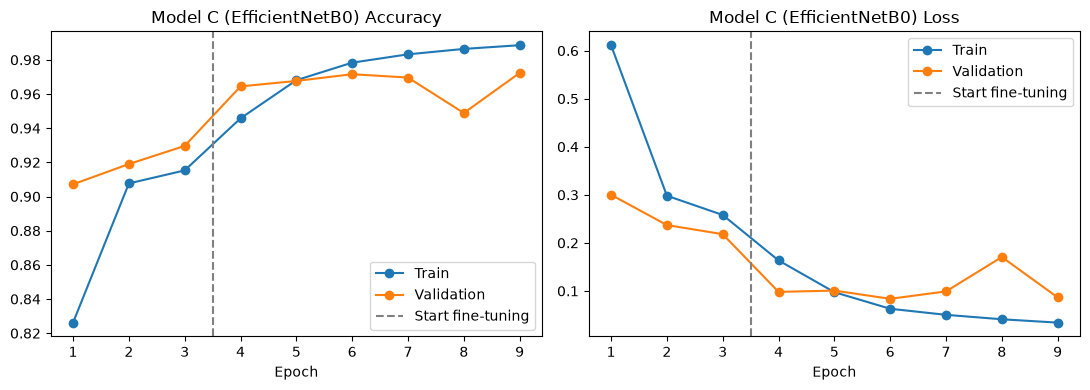

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in ((axes[0], "accuracy", "Accuracy"),
                          (axes[1], "loss", "Loss")):
    ax.plot(history_df["epoch"], history_df[metric], marker="o",
            label="Train")
    ax.plot(history_df["epoch"], history_df[f"val_{metric}"], marker="o",
            label="Validation")
    ax.axvline(HEAD_EPOCHS + 0.5, color="grey", linestyle="--",
               label="Start fine-tuning")
    ax.set(title=f"Model C (EfficientNetB0) {title}", xlabel="Epoch")
    ax.legend()
plt.tight_layout()
fig.savefig(RESULTS_DIR / "efficientnet_curves.png", dpi=160,
            bbox_inches="tight")
plt.show()

## 7. Test-set evaluation

I evaluate the restored best checkpoint once on the 4,050 held-out test
images. Accuracy is the headline number. Macro precision, recall, and F1 weight
every class equally, so a weak class such as Pasture (300 test images) counts
as much as a large one. I also save every test prediction so that the
comparison notebook can run paired tests.

In [10]:
test_probs, test_preds, test_metrics = evaluate_on_test(model_c)
print(f"Test accuracy: {test_metrics['test_accuracy']:.4f}")
print(f"Macro F1:      {test_metrics['test_macro_f1']:.4f}")
print(classification_report(y_test, test_preds, labels=list(range(10)),
                            target_names=CLASS_NAMES, digits=4,
                            zero_division=0))

per_class = pd.DataFrame(classification_report(
    y_test, test_preds, labels=list(range(10)), target_names=CLASS_NAMES,
    output_dict=True, zero_division=0)).T.loc[CLASS_NAMES]
per_class.to_csv(RESULTS_DIR / "efficientnet_per_class.csv")

pred_df = pd.DataFrame({
    "filename": f_test, "label": y_test, "pred": test_preds,
    "confidence": test_probs.max(axis=1).round(5),
})
for k, name in enumerate(CLASS_NAMES):
    pred_df[f"p_{name}"] = test_probs[:, k].round(5)
pred_df.to_csv(RESULTS_DIR / "efficientnet_test_predictions.csv",
               index=False)

Test accuracy: 0.9780
Macro F1:      0.9777
                      precision    recall  f1-score   support

          AnnualCrop     0.9863    0.9578    0.9718       450
              Forest     0.9494    1.0000    0.9740       450
HerbaceousVegetation     0.9818    0.9600    0.9708       450
             Highway     0.9814    0.9867    0.9840       375
          Industrial     0.9973    0.9787    0.9879       375
             Pasture     0.9761    0.9533    0.9646       300
       PermanentCrop     0.9556    0.9760    0.9657       375
         Residential     0.9804    1.0000    0.9901       450
               River     0.9737    0.9867    0.9801       375
             SeaLake     1.0000    0.9756    0.9876       450

            accuracy                         0.9780      4050
           macro avg     0.9782    0.9775    0.9777      4050
        weighted avg     0.9784    0.9780    0.9780      4050



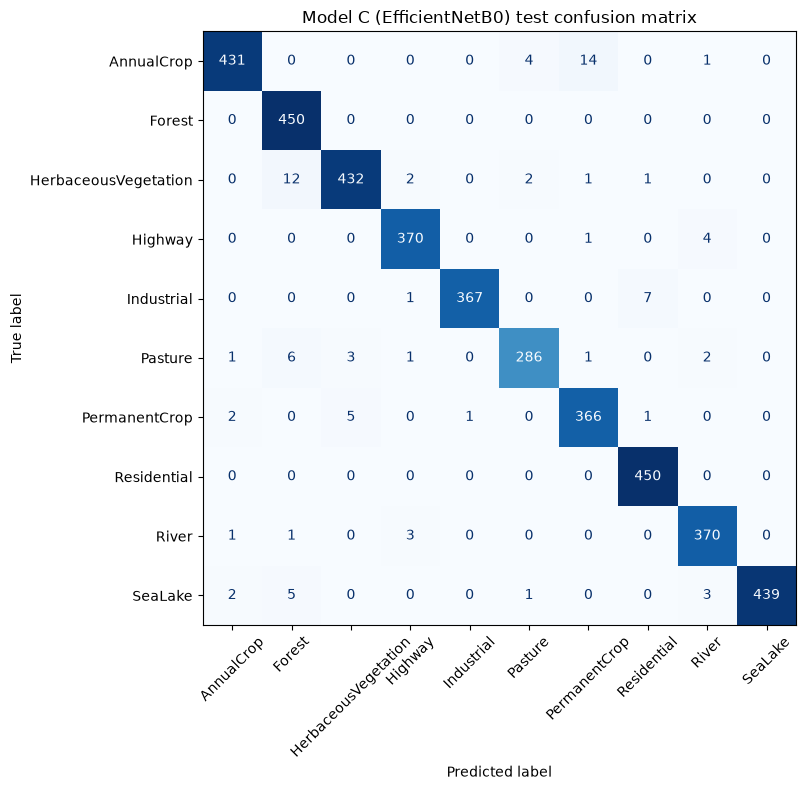

,true,predicted,count
0,AnnualCrop,PermanentCrop,14
1,HerbaceousVegetation,Forest,12
2,Industrial,Residential,7
3,Pasture,Forest,6
4,PermanentCrop,HerbaceousVegetation,5
5,SeaLake,Forest,5
6,Highway,River,4
7,AnnualCrop,Pasture,4


In [11]:
cm = confusion_matrix(y_test, test_preds, labels=list(range(10)))
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    RESULTS_DIR / "efficientnet_confusion.csv")

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", values_format="d",
    colorbar=False)
ax.set_title("Model C (EfficientNetB0) test confusion matrix")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "efficientnet_confusion.png", dpi=160,
            bbox_inches="tight")
plt.show()

off_diag = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]))
            for i in range(10) for j in range(10) if i != j and cm[i, j]]
top_confusions = (pd.DataFrame(off_diag, columns=["true", "predicted",
                                                  "count"])
                  .sort_values("count", ascending=False).head(8))
display(top_confusions.reset_index(drop=True))

## 8. Save the Model C results

The JSON uses the same keys as Model A's file, so the comparison notebook can
read all three models the same way.

In [12]:
results = {
    "model": "C - EfficientNetB0",
    "dataset": "EuroSAT RGB (Zenodo)",
    "split_seed": class_map["split_seed"],
    "train_seed": SEED,
    "keras_backend": BACKEND,
    "input_size": IMG_SIZE,
    "train_count": int(len(y_train)),
    "val_count": int(len(y_val)),
    "test_count": int(len(y_test)),
    "best_epoch": int(best_row["epoch"]),
    "best_epoch_train_accuracy": float(best_row["accuracy"]),
    "best_epoch_validation_accuracy": float(best_row["val_accuracy"]),
    "best_epoch_accuracy_gap": float(best_row["accuracy"]
                                     - best_row["val_accuracy"]),
    "best_validation_loss": float(best_row["val_loss"]),
    **test_metrics,
    "train_minutes": round(train_seconds / 60, 2),
    "parameters": int(model_c.count_params()),
}
(RESULTS_DIR / "efficientnet_metrics.json").write_text(
    json.dumps(results, indent=2) + "\n")
display(pd.Series(results, name="Value").to_frame())

,Value
model,C - EfficientNetB0
dataset,EuroSAT RGB (Zenodo)
split_seed,42
train_seed,42
keras_backend,torch
input_size,224
train_count,18900
val_count,4050
test_count,4050
best_epoch,6


## 9. Error analysis: what does the model get wrong?

Below are the misclassified test tiles with the highest confidence. These are
the cases where the model is "confidently wrong". They show whether the
errors are real model mistakes or tiles that are ambiguous even to a person.

Misclassified: 89 of 4050 (2.20%)


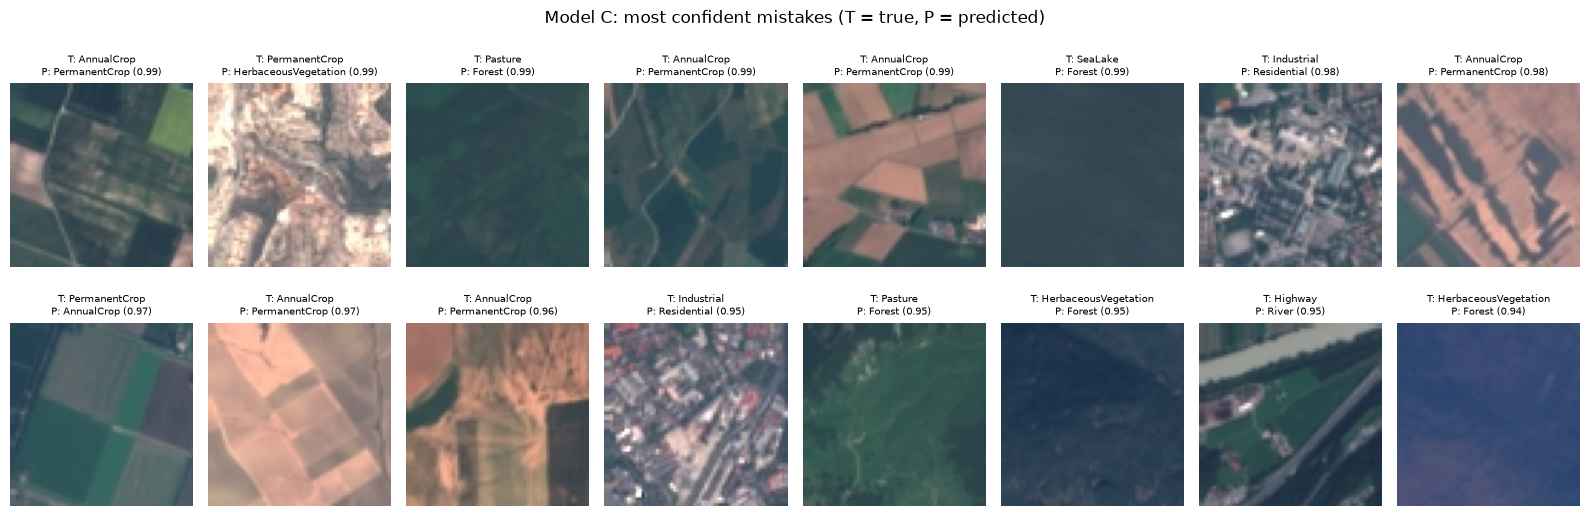

In [13]:
wrong = pred_df[pred_df["label"] != pred_df["pred"]].sort_values(
    "confidence", ascending=False)
print(f"Misclassified: {len(wrong)} of {len(pred_df)} "
      f"({len(wrong) / len(pred_df):.2%})")

show = wrong.head(16)
fig, axes = plt.subplots(2, 8, figsize=(16, 5.6))
for ax, (_, row) in zip(axes.flat, show.iterrows()):
    idx = int(np.where(f_test == row["filename"])[0][0])
    ax.imshow(x_test[idx])
    ax.set_title(f"T: {CLASS_NAMES[row['label']]}\n"
                 f"P: {CLASS_NAMES[row['pred']]} ({row['confidence']:.2f})",
                 fontsize=7.5)
    ax.axis("off")
for ax in list(axes.flat)[len(show):]:
    ax.axis("off")
fig.suptitle("Model C: most confident mistakes (T = true, P = predicted)")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "efficientnet_misclassified.png", dpi=160,
            bbox_inches="tight")
plt.show()

## 10. Grad-CAM: where does the model look?

Grad-CAM (Selvaraju et al., 2017) weights each channel $k$ of the last
convolutional feature map $A^k$ by the average gradient of the class score
$y^c$:
$\alpha_k^c = \frac{1}{Z}\sum_{i,j}\partial y^c/\partial A^k_{ij}$. The
heatmap is then $L^c=\mathrm{ReLU}(\sum_k \alpha_k^c A^k)$. For B0 that
feature map is `top_activation`, which is 7 × 7 at a 224-px input. I upsample
the heatmap to the 64 × 64 tile.

Getting the gradient is backend-specific (`tf.GradientTape` or
`torch.autograd`). Both branches compute the same quantity, and the rest of
the function is shared.

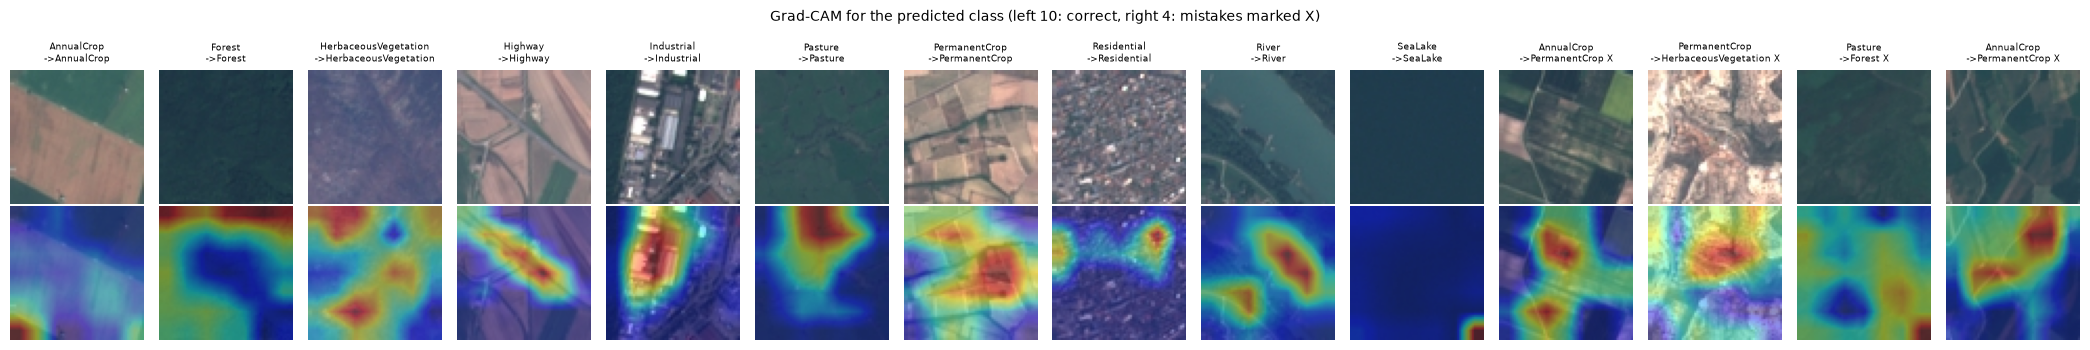

In [14]:
def grad_cam(model, images, class_ids):
    """Grad-CAM heatmaps (N, 64, 64) in [0, 1] for the given class ids."""
    resize = model.get_layer("resize")
    backbone_layer = model.get_layer(backbone.name)
    gap, dense = model.get_layer("gap"), model.get_layer("head_dense")
    feats = backbone_layer(resize(keras.ops.convert_to_tensor(
        images.astype("float32"))), training=False)
    onehot = keras.ops.one_hot(keras.ops.convert_to_tensor(class_ids),
                               NUM_CLASSES)
    if BACKEND == "torch":
        feats = feats.detach().requires_grad_(True)
        score = keras.ops.sum(dense(gap(feats)) * onehot)
        grads = torch.autograd.grad(score, feats)[0]
    else:
        with tf.GradientTape() as tape:
            tape.watch(feats)
            score = keras.ops.sum(dense(gap(feats)) * onehot)
        grads = tape.gradient(score, feats)
    feats = keras.ops.convert_to_numpy(feats)
    grads = keras.ops.convert_to_numpy(grads)
    weights = grads.mean(axis=(1, 2), keepdims=True)
    cams = np.maximum((weights * feats).sum(axis=-1), 0)
    cams /= cams.max(axis=(1, 2), keepdims=True) + 1e-8
    cams = keras.ops.convert_to_numpy(
        keras.ops.image.resize(cams[..., None], (64, 64)))[..., 0]
    return cams


# One correct example per class, plus the four most confident mistakes.
rng = np.random.default_rng(SEED)
correct_idx = []
for k in range(NUM_CLASSES):
    pool = np.where((y_test == k) & (test_preds == k))[0]
    if len(pool) == 0:  # no correct tile for this class: show any tile
        pool = np.where(y_test == k)[0]
    correct_idx.append(int(rng.choice(pool)))
wrong_idx = [int(np.where(f_test == f)[0][0])
             for f in wrong.head(4)["filename"]]
idx = np.array(correct_idx + wrong_idx)
cams = grad_cam(model_c, x_test[idx], test_preds[idx])

fig, axes = plt.subplots(2, len(idx), figsize=(len(idx) * 1.5, 3.6))
for col, (i, cam) in enumerate(zip(idx, cams)):
    axes[0, col].imshow(x_test[i])
    ok = "" if y_test[i] == test_preds[i] else " X"
    axes[0, col].set_title(f"{CLASS_NAMES[y_test[i]]}\n->"
                           f"{CLASS_NAMES[test_preds[i]]}{ok}", fontsize=6.5)
    axes[1, col].imshow(x_test[i])
    axes[1, col].imshow(cam, cmap="jet", alpha=0.45)
    for row in (0, 1):
        axes[row, col].axis("off")
fig.suptitle("Grad-CAM for the predicted class (left 10: correct, "
             "right 4: mistakes marked X)", fontsize=10)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "efficientnet_gradcam.png", dpi=160,
            bbox_inches="tight")
plt.show()

## 11. Repeated runs and the input-resolution study

One training run can be lucky. The grading rubric also asks for results
gathered over several runs. So I retrain the model with the exact same recipe:

* **Seed study:** 224 px with seeds 42 (the run above), 7, and 123. The seed
  changes the head initialisation, the augmentation, and the batch order.
  The data split stays fixed.
* **Resolution study:** seed 42 at 64 px (native, no upsampling), 128 px,
  and 224 px.

Each run adds a row to `results/efficientnet_runs.csv`. When the notebook is
re-run, it skips runs that are already in the file, so a disconnected Colab
session can resume where it stopped. Note that GPU training is not bit-exact,
so a repeated seed can differ slightly.

In [15]:
RUNS_PATH = RESULTS_DIR / "efficientnet_runs.csv"
EXPERIMENTS = [  # (input size, seed)
    (224, 42), (224, 7), (224, 123),
    (128, 42), (64, 42),
]
RUN_EXTRA_EXPERIMENTS = True

runs_df = (pd.read_csv(RUNS_PATH) if RUNS_PATH.exists()
           else pd.DataFrame(columns=["input_size", "seed"]))
main_key = (IMG_SIZE, SEED)


def record_run(size, seed, hist, metrics, minutes, params):
    """Append one run's results to the runs table and save it."""
    global runs_df
    fine = hist[hist["stage"] == "fine"]
    best = fine.loc[fine["val_loss"].idxmin()]
    row = {"input_size": size, "seed": seed, "keras_backend": BACKEND,
           "epochs_run": int(hist["epoch"].max()),
           "best_epoch": int(best["epoch"]),
           "best_val_accuracy": float(best["val_accuracy"]),
           "best_val_loss": float(best["val_loss"]),
           **metrics, "train_minutes": round(minutes, 2),
           "parameters": params}
    runs_df = pd.concat([runs_df, pd.DataFrame([row])], ignore_index=True)
    runs_df.to_csv(RUNS_PATH, index=False)


done = set(zip(runs_df["input_size"].astype(int), runs_df["seed"].astype(int)))
if main_key not in done:
    record_run(IMG_SIZE, SEED, history_df, test_metrics, train_seconds / 60,
               model_c.count_params())
    done.add(main_key)

for size, seed in EXPERIMENTS:
    if not RUN_EXTRA_EXPERIMENTS or (size, seed) in done:
        continue
    print(f"\n=== EfficientNetB0 | input {size}px | seed {seed} ===")
    keras.backend.clear_session()
    model, bb = build_efficientnet(size, seed)
    start = time.time()
    hist = train_two_stage(model, bb, verbose=2)
    minutes = (time.time() - start) / 60
    _, _, metrics = evaluate_on_test(model)
    record_run(size, seed, hist, metrics, minutes, model.count_params())
    print(f"test acc {metrics['test_accuracy']:.4f} | "
          f"macro F1 {metrics['test_macro_f1']:.4f} | {minutes:.1f} min")
    del model, bb

display(runs_df)

W1118 21:30:42.411000 2084 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels



=== EfficientNetB0 | input 224px | seed 7 ===


Epoch 1/3


296/296 - 95s - 322ms/step - accuracy: 0.8281 - loss: 0.6128 - val_accuracy: 0.9106 - val_loss: 0.2993


Epoch 2/3


296/296 - 95s - 321ms/step - accuracy: 0.9040 - loss: 0.3018 - val_accuracy: 0.9178 - val_loss: 0.2414


... (81 outputs left out)

Epoch 8/8


296/296 - 92s - 311ms/step - accuracy: 0.9856 - loss: 0.0421 - val_accuracy: 0.9598 - val_loss: 0.1255 - learning_rate: 1.2500e-05


test acc 0.9637 | macro F1 0.9632 | 15.2 min


,input_size,seed,keras_backend,epochs_run,best_epoch,best_val_accuracy,best_val_loss,test_loss,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,inference_ms_per_image,train_minutes,parameters
0,224,42,torch,9.0,6.0,0.971605,0.083636,0.063465,0.978025,0.978197,0.977467,0.977670,3.562571,26.58,4062381.0
1,224,7,torch,9.0,6.0,0.975802,0.074489,0.059155,0.982222,0.981883,0.981978,0.981866,3.338117,26.35,4062381.0
2,224,123,torch,11.0,9.0,0.974815,0.079356,0.069402,0.979012,0.979259,0.979511,0.979067,3.455887,33.85,4062381.0
3,128,42,torch,11.0,9.0,0.972099,0.083037,0.064973,0.976049,0.975989,0.975467,0.975520,1.631232,18.92,4062381.0
4,64,42,torch,11.0,9.0,0.959506,0.124555,0.109368,0.963704,0.964671,0.962667,0.963235,1.510772,15.15,4062381.0


224 px over 3 seeds: accuracy 0.9798 ± 0.0022, macro F1 0.9795 ± 0.0021


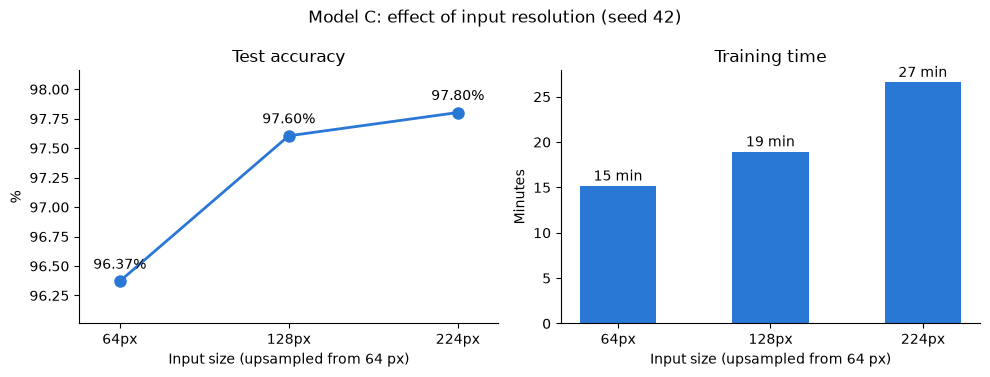

In [16]:
seed_runs = runs_df[runs_df["input_size"].astype(int) == 224]
summary = seed_runs[["test_accuracy", "test_macro_f1"]].agg(["mean", "std"])
print(f"224 px over {len(seed_runs)} seeds: "
      f"accuracy {summary.loc['mean', 'test_accuracy']:.4f} "
      f"± {summary.loc['std', 'test_accuracy']:.4f}, "
      f"macro F1 {summary.loc['mean', 'test_macro_f1']:.4f} "
      f"± {summary.loc['std', 'test_macro_f1']:.4f}")

res = (runs_df[runs_df["seed"].astype(int) == SEED]
       .assign(input_size=lambda d: d["input_size"].astype(int))
       .sort_values("input_size"))
# Two panels with their own y-axes instead of one twin-axis chart.
labels = [f"{s}px" for s in res["input_size"]]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.plot(labels, res["test_accuracy"] * 100, marker="o", ms=8, lw=2,
         color="#2a78d6")
for x, acc in zip(labels, res["test_accuracy"] * 100):
    ax1.annotate(f"{acc:.2f}%", (x, acc), textcoords="offset points",
                 xytext=(0, 9), ha="center")
ax1.margins(x=0.12, y=0.25)
ax1.set(title="Test accuracy", xlabel="Input size (upsampled from 64 px)",
        ylabel="%")
ax2.bar(labels, res["train_minutes"], width=0.5, color="#2a78d6")
for x, minutes in zip(labels, res["train_minutes"]):
    ax2.annotate(f"{minutes:.0f} min", (x, minutes),
                 textcoords="offset points", xytext=(0, 4), ha="center")
ax2.set(title="Training time", xlabel="Input size (upsampled from 64 px)",
        ylabel="Minutes")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Model C: effect of input resolution (seed 42)")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "efficientnet_resolution.png", dpi=160,
            bbox_inches="tight")
plt.show()

## 12. Findings for Model C

* **Test result (seed 42, 224 px):** 97.80% accuracy and 0.9777 macro-F1
  on the 4,050 shared test tiles, with 89 errors. Model B makes 181 and
  Model A makes 443. Every class has F1 ≥ 0.96. The weakest are Pasture
  (0.965) and PermanentCrop (0.966).
* **Stable across seeds:** 97.98% ± 0.22% (mean ± SD over seeds 42, 7, and
  123), so the result is not a lucky initialisation.
* **Little overfitting:** at the selected epoch (epoch 6), training accuracy
  is 97.8% and validation accuracy is 97.2%. After that, validation loss
  rises while training loss keeps falling, and EarlyStopping restores
  epoch 6.
* **Resolution:** 96.37% at 64 px, 97.60% at 128 px, and 97.80% at 224 px.
  Upsampling helps because the ImageNet filters were learned at 224 px, but
  most of the gain arrives by 128 px.
* **Errors:** most mistakes are AnnualCrop ↔ PermanentCrop, plus dark,
  low-texture tiles predicted as Forest. Many of these tiles are ambiguous
  even to a person. Grad-CAM shows the model attending to roads, water
  channels, and buildings, not to borders or artefacts.

The cross-model comparison, significance tests, and final model choice are
in `04_Model_Comparison.ipynb`. The trained checkpoint stays in `models/`
and is **not** committed. `results/` holds the small CSV, JSON, and PNG
outputs.